<a href="https://colab.research.google.com/github/Shamil2007/Machine-Learning/blob/main/Linear_models_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
plt.rc('font', size=14)
plt.rc('axes', labelsize = 14, titlesize = 14)
plt.rc('legend', fontsize = 14)
plt.rc('xtick', labelsize = 10)
plt.rc('ytick', labelsize = 10)

In [3]:
np.random.seed(42)

n = 100 # total number of data
X = 2 * np.random.rand(n, 1)
y = 4 + 3 * X + np.random.randn(n, 1) # we are adding a little bit of random noise

rand -> Numbers spread evenly across a specific range. Every number has an equal chance of being picked.

randn -> Numbers following a bell curve centered at 0 with a standard deviation of 1 like normal distribution.

In [4]:
pd.DataFrame({"X": X.flatten(), "y": y.flatten()}).head()

,X,y
0,0.749080,6.334288
1,1.901429,9.405278
2,1.463988,8.483724
3,1.197317,5.604382
4,0.312037,4.716440


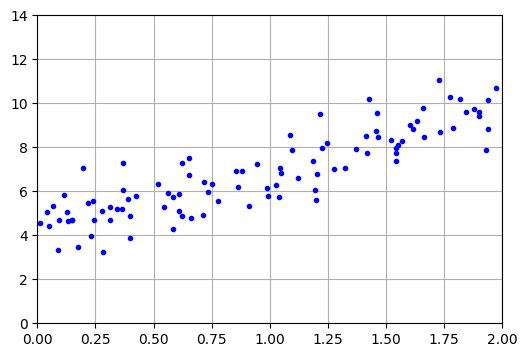

In [5]:
plt.figure(figsize = (6, 4))
plt.plot(X, y , 'b.')
plt.xlabel('')
plt.ylabel('', rotation = 0)
plt.axis([0, 2, 0, 14])
plt.grid();

In [6]:
matrix_a = np.array([[1, 2],[3, 4]])
matrix_b = np.array([[5, 6],[7, 8]])

result = matrix_a @ matrix_b
result1 = np.dot(matrix_a, matrix_b)

print('Matrix A:')
print(matrix_a)
print('\nMatrix b:')
print(matrix_b)
print('\nResult of Matrix multiplication (A @ B):')
print(result1)

Matrix A:
[[1 2]
 [3 4]]

Matrix b:
[[5 6]
 [7 8]]

Result of Matrix multiplication (A @ B):
[[19 22]
 [43 50]]


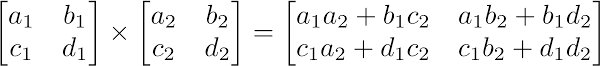

In [7]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X) # y = wx + b
X_b[:5]

array([[1.        , 0.74908024],
       [1.        , 1.90142861],
       [1.        , 1.46398788],
       [1.        , 1.19731697],
       [1.        , 0.31203728]])

In [8]:
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
theta_best

array([[4.21509616],
       [2.77011339]])

This single matrix multiplication calculates the exact optimal values for $b$ (intercept) and $w$ (slope) in one shot.

In [9]:
X_pred = np.array([[0], [2]])
X_pred_b = add_dummy_feature(X_pred)

y_pred = X_pred_b @ theta_best

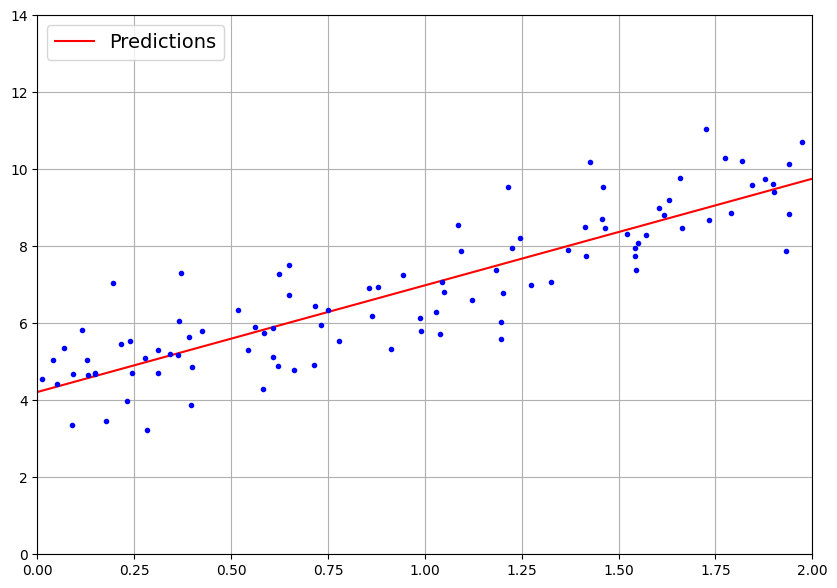

In [10]:
plt.figure(figsize=(10, 7))
plt.plot(X_pred, y_pred, 'r-', label='Predictions')
plt.plot(X, y, 'b.')

plt.xlabel('')
plt.ylabel('', rotation = 0)
plt.axis([0, 2, 0, 14])
plt.grid()
plt.legend(loc='upper left')

plt.show()

In [11]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)
lin_reg.intercept_, lin_reg.coef_

(array([4.21509616]), array([[2.77011339]]))

lin_reg.intercept_: Returns the learned bias/intercept parameter ($b$)

lin_reg.coef_: Returns the learned feature slope weight ($w$)

# Gradient Descent

## Batch Gradient Descent

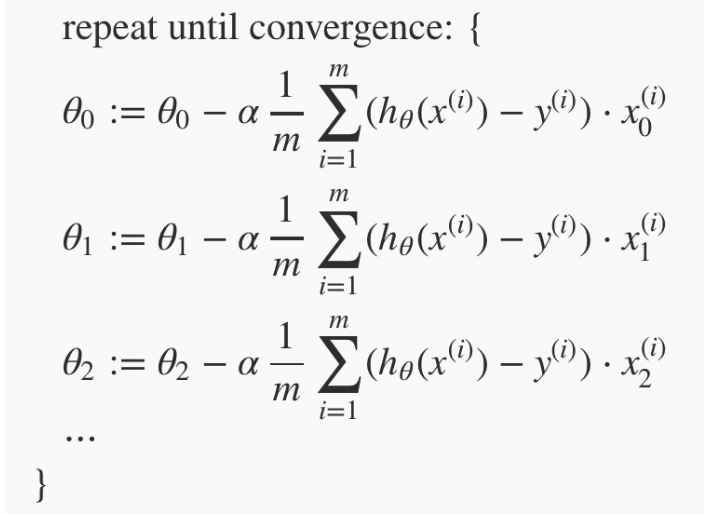

In [12]:
eta = 0.1   # learning rate
n_epochs = 1000
m = len(X_b)      # number of data

np.random.seed(42)
theta = np.random.randn(2,1)    # randomly initialize model parameters

for epoch in range(n_epochs):
  gradient = 1 / m * 2 * X_b.T @ (X_b @ theta - y)
  theta = theta - eta * gradient

In [13]:
theta

array([[4.21509616],
       [2.77011339]])

- Why "Batch"? In every single iteration (epoch), the algorithm processes the entire dataset ($m$ samples) to compute the exact gradient.

- How it works:

    1. Starts at a random point ($\boldsymbol{\theta}$ initialization).
    2. Measures the slope (gradient) of the error curve across all $m$ data points.
    3. Takes a step downhill of size $\eta \times \text{gradient}$.
    4. Repeats for n_epochs until reaching the flat bottom of the loss bowl.

## Stochastic Gradient Descend

**What Makes This Different from Batch GD?**

In Batch Gradient Descent, you calculate gradients using the entire dataset ($m$ samples) at once. Here, you pick one single random instance ($x_i, y_i$) at each step to update the weights.

In [14]:
np.random.seed(42)
eta = 0.1
m = len(X_b)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
  for iteration in range(m):
    random_index = np.random.randint(m)
    xi = X_b[random_index : random_index + 1]
    yi = y[random_index : random_index + 1]
    gradients = 2 * xi.T @ (xi @ theta - yi)
    theta = theta - eta * gradients

In [15]:
theta

array([[4.17686315],
       [2.85986577]])

In [16]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, penalty=None, eta0 = 0.01,
                       n_iter_no_change=100, random_state=42)
sgd_reg.fit(X, y.ravel())

SGDRegressor(n_iter_no_change=100, penalty=None, random_state=42, tol=1e-05)

In [17]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.21278812]), array([2.77270267]))

1. **tol=1e-5:** Sets the loss threshold. If the model's loss improves by less than 1e-5 compared to the previous epoch, Scikit-Learn considers that no meaningful improvement was made.

2. **n_iter_no_change=100:** Tells the model: "If the loss fails to improve by at least tol for 100 consecutive epochs, stop training early."

3. **max_iter=1000:** The hard limit on total epochs. Training stops after 1000 epochs even if the stopping condition hasn't been triggered yet.

4. **y.ravel():** Flattens y from a 2D column matrix (100, 1) into a 1D array (100,) because SGDRegressor expects 1D targets.

##Mini Batch Gradient Descend

In [18]:
from math import ceil

n_epochs = 50
eta = 0.1
m = len(X_b)
minibatch_size = 20
n_batches_per_epoch = ceil(m / minibatch_size)

np.random.seed(42)
theta = np.random.randn(2, 1)

for epoch in range(n_epochs):
  shuffled_indices = np.random.permutation(m) # Shuffles all data row indices at the start of every epoch so each mini-batch gets a fresh, random mix of samples.
  X_b_shuffled = X_b[shuffled_indices]
  y_shuffled = y[shuffled_indices]
  for iteration in range(0, n_batches_per_epoch):
    idx = iteration * minibatch_size
    xi = X_b_shuffled[idx : idx + minibatch_size]
    yi = y_shuffled[idx : idx + minibatch_size]
    gradients = 2 / minibatch_size * xi.T @ (xi @ theta - yi)
    theta = theta - eta * gradients

**Why Mini-Batch GD is the Industry Standard**


*   **Hardware Optimization:** Matrix math on chunks of 32, 64, or 128 rows runs extremely fast on modern CPUs/GPUs due to parallel processing.
*   **Less Noise Than SGD:** Averaging over 20 points smooths out individual outlier noise, making convergence toward the minimum much cleaner.
* **Faster Than Batch GD:** It updates parameters multiple times per epoch rather than waiting to process the entire dataset first.

In [19]:
theta

array([[4.22023943],
       [2.7704472 ]])

#Polynomial Regression

In [20]:
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3
y = 0.5 * X ** 2 + X + 2 + np.random.randn(m, 1)

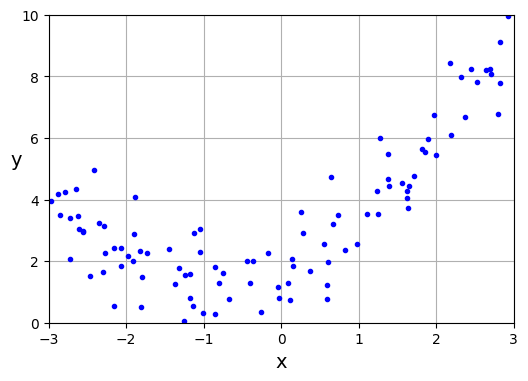

In [21]:
plt.figure(figsize = (6, 4))
plt.plot(X, y, 'b.')
plt.xlabel('x')
plt.ylabel('y', rotation = 0)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

In [22]:
lin_reg.fit(X, y)

predictions = lin_reg.predict([[-3], [3]])
predictions

array([[1.03315352],
       [6.09487734]])

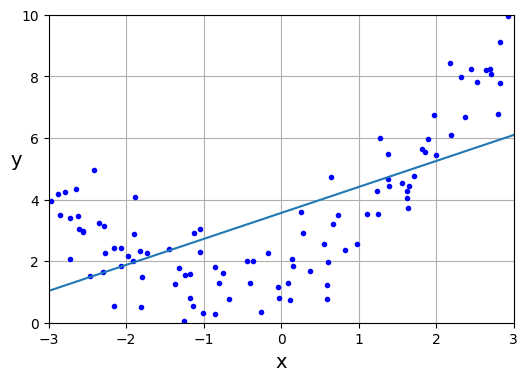

In [23]:
plt.figure(figsize = (6, 4))
plt.plot(X, y, 'b.')
plt.plot([-3,3],predictions)
plt.xlabel('x')
plt.ylabel('y', rotation = 0)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

When your data follows a curve (like a parabola), a straight line model ($y = \theta_0 + \theta_1 x$) will underfit because it simply cannot bend.

To capture that curve using Polynomial Regression, you transform your inputs by adding higher-degree terms like $x^2$:
$$y = \theta_0 + \theta_1 x + \theta_2 x^2$$

In [24]:
from sklearn.preprocessing import PolynomialFeatures

In [25]:
poly_features = PolynomialFeatures(degree=2, include_bias = False)
X_poly = poly_features.fit_transform(X)
X_poly[0]

array([-0.75275929,  0.56664654])

In [26]:
X[0], X[0] ** 2

(array([-0.75275929]), array([0.56664654]))

In [27]:
lin_reg.fit(X_poly, y)
lin_reg.intercept_, lin_reg.coef_

(array([1.78134581]), array([[0.93366893, 0.56456263]]))

In [28]:
model = lin_reg.fit(X_poly, y)
poly_predict = model.predict

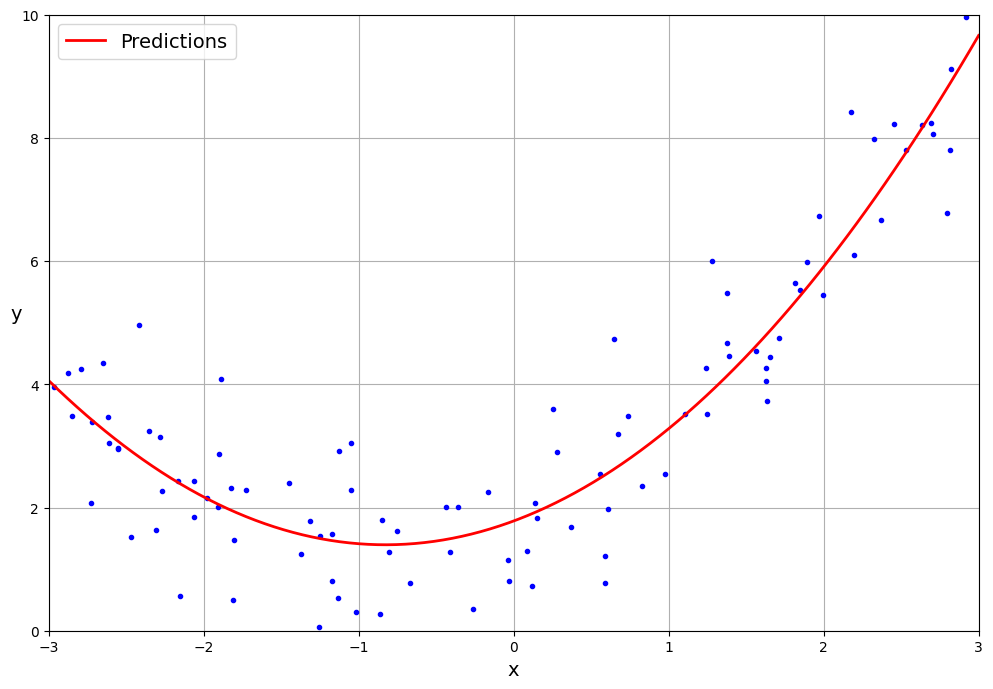

In [29]:
X_new = np.linspace(-3, 3, 100).reshape(100, 1)
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize= (12, 8))
plt.plot(X, y, 'b.')
plt.plot(X_new, y_new, 'r-', linewidth = 2, label='Predictions')
plt.xlabel('x')
plt.ylabel('y', rotation = 0)
plt.legend(loc='upper left')
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

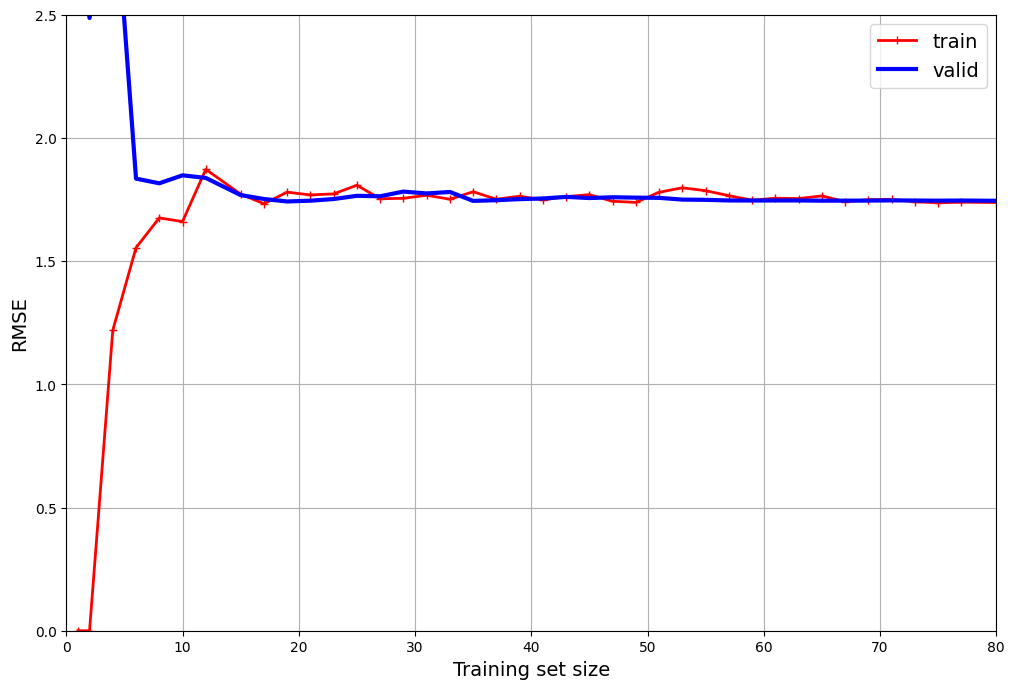

In [30]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(), X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5,
    scoring='neg_root_mean_squared_error'
)

train_errors = -train_scores.mean(axis = 1)
valid_errors = -valid_scores.mean(axis = 1)

plt.figure(figsize = (12, 8))
plt.plot(train_sizes, train_errors, 'r-+', linewidth = 2, label='train')
plt.plot(train_sizes, valid_errors, 'b-', linewidth = 3, label='valid')

plt.xlabel('Training set size')
plt.ylabel('RMSE')
plt.grid()
plt.legend(loc='upper right')
plt.axis([0, 80, 0, 2.5])

plt.show()

This plot shows Learning Curves for a model that is underfitting (high bias).

Both curves meet and plateau at a high error rate.

This means the model is too simple for the data. Adding more training data will not improve performance—you need a more complex model or better features (like adding polynomial features).

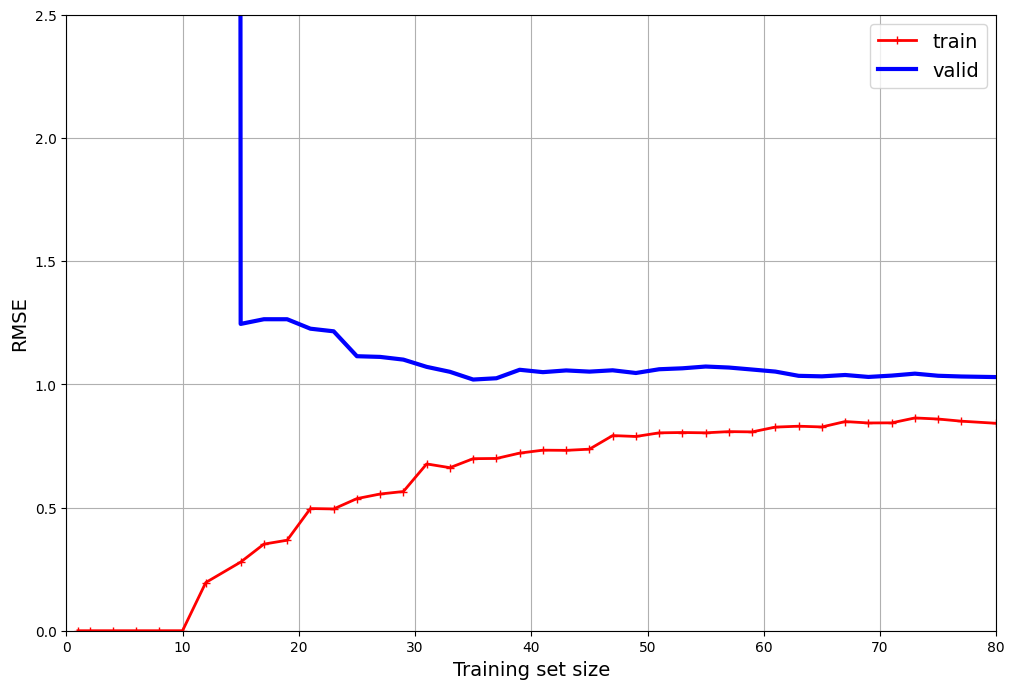

In [31]:
from sklearn.pipeline import make_pipeline

polynomial_regression = make_pipeline(
    PolynomialFeatures(degree=10, include_bias = False), # Polynomial added
    LinearRegression()
)


train_sizes, train_scores, valid_scores = learning_curve(
    polynomial_regression, X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5,
    scoring='neg_root_mean_squared_error'
)

train_errors = -train_scores.mean(axis = 1)
valid_errors = -valid_scores.mean(axis = 1)

plt.figure(figsize = (12, 8))
plt.plot(train_sizes, train_errors, 'r-+', linewidth = 2, label='train')
plt.plot(train_sizes, valid_errors, 'b-', linewidth = 3, label='valid')

plt.xlabel('Training set size')
plt.ylabel('RMSE')
plt.grid()
plt.legend(loc='upper right')
plt.axis([0, 80, 0, 2.5])

plt.show()

This plot shows Learning Curves for a model that is overfitting (high variance).

The defining sign here is the persistent gap between the training and validation curves.   This means the model performs significantly better on training data than on unseen data. To fix this, you can:

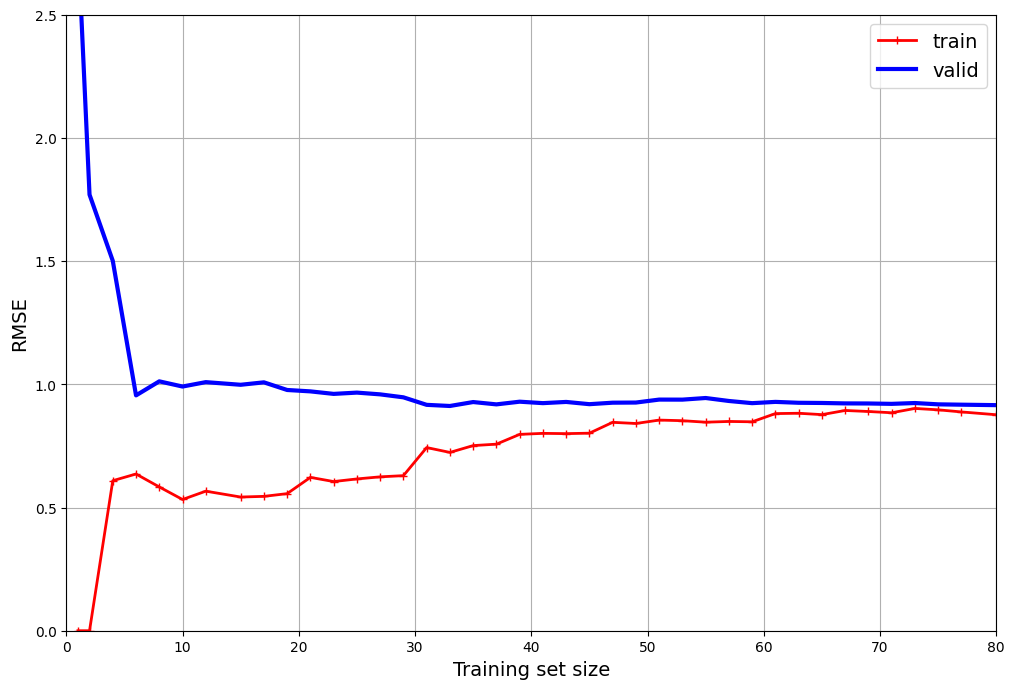

In [32]:
from sklearn.pipeline import make_pipeline

polynomial_regression = make_pipeline(
    PolynomialFeatures(degree=2, include_bias = False),
    LinearRegression()
)


train_sizes, train_scores, valid_scores = learning_curve(
    polynomial_regression, X, y, train_sizes=np.linspace(0.01, 1.0, 40), cv=5,
    scoring='neg_root_mean_squared_error'
)

train_errors = -train_scores.mean(axis = 1)
valid_errors = -valid_scores.mean(axis = 1)

plt.figure(figsize = (12, 8))
plt.plot(train_sizes, train_errors, 'r-+', linewidth = 2, label='train')
plt.plot(train_sizes, valid_errors, 'b-', linewidth = 3, label='valid')

plt.xlabel('Training set size')
plt.ylabel('RMSE')
plt.grid()
plt.legend(loc='upper right')
plt.axis([0, 80, 0, 2.5])

plt.show()

#Regularized Linear Models

## Ridge Regression (L2)

In [33]:
np.random.seed(42)
m = 20
X = 3 * np.random.rand(m, 1)
y = 1 + 0.5 * X + np.random.randn(m, 1) / 1.5
X_new = np.linspace(0, 3, 100).reshape(100, 1)

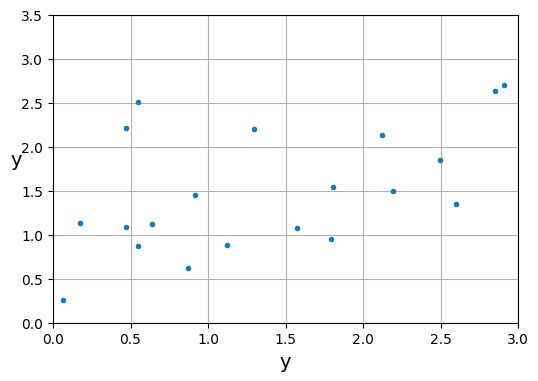

In [34]:
plt.figure(figsize=(6, 4))
plt.plot(X, y, '.')
plt.xlabel('y')
plt.ylabel('y', rotation=0)
plt.axis([0, 3, 0, 3.5])
plt.grid()
plt.show()

In [35]:
from sklearn.linear_model import Ridge

ridge_reg = Ridge(alpha = 0.1, solver='cholesky')
ridge_reg.fit(X, y)
ridge_reg.predict([[1.5]])

array([1.55325833])

- **alpha=0.1:** Sets the penalty strength (higher values force model weights to stay smaller to prevent overfitting).

- **solver='cholesky':** Uses Cholesky matrix decomposition to calculate the exact closed-form solution directly (an optimized version of the Normal Equation).

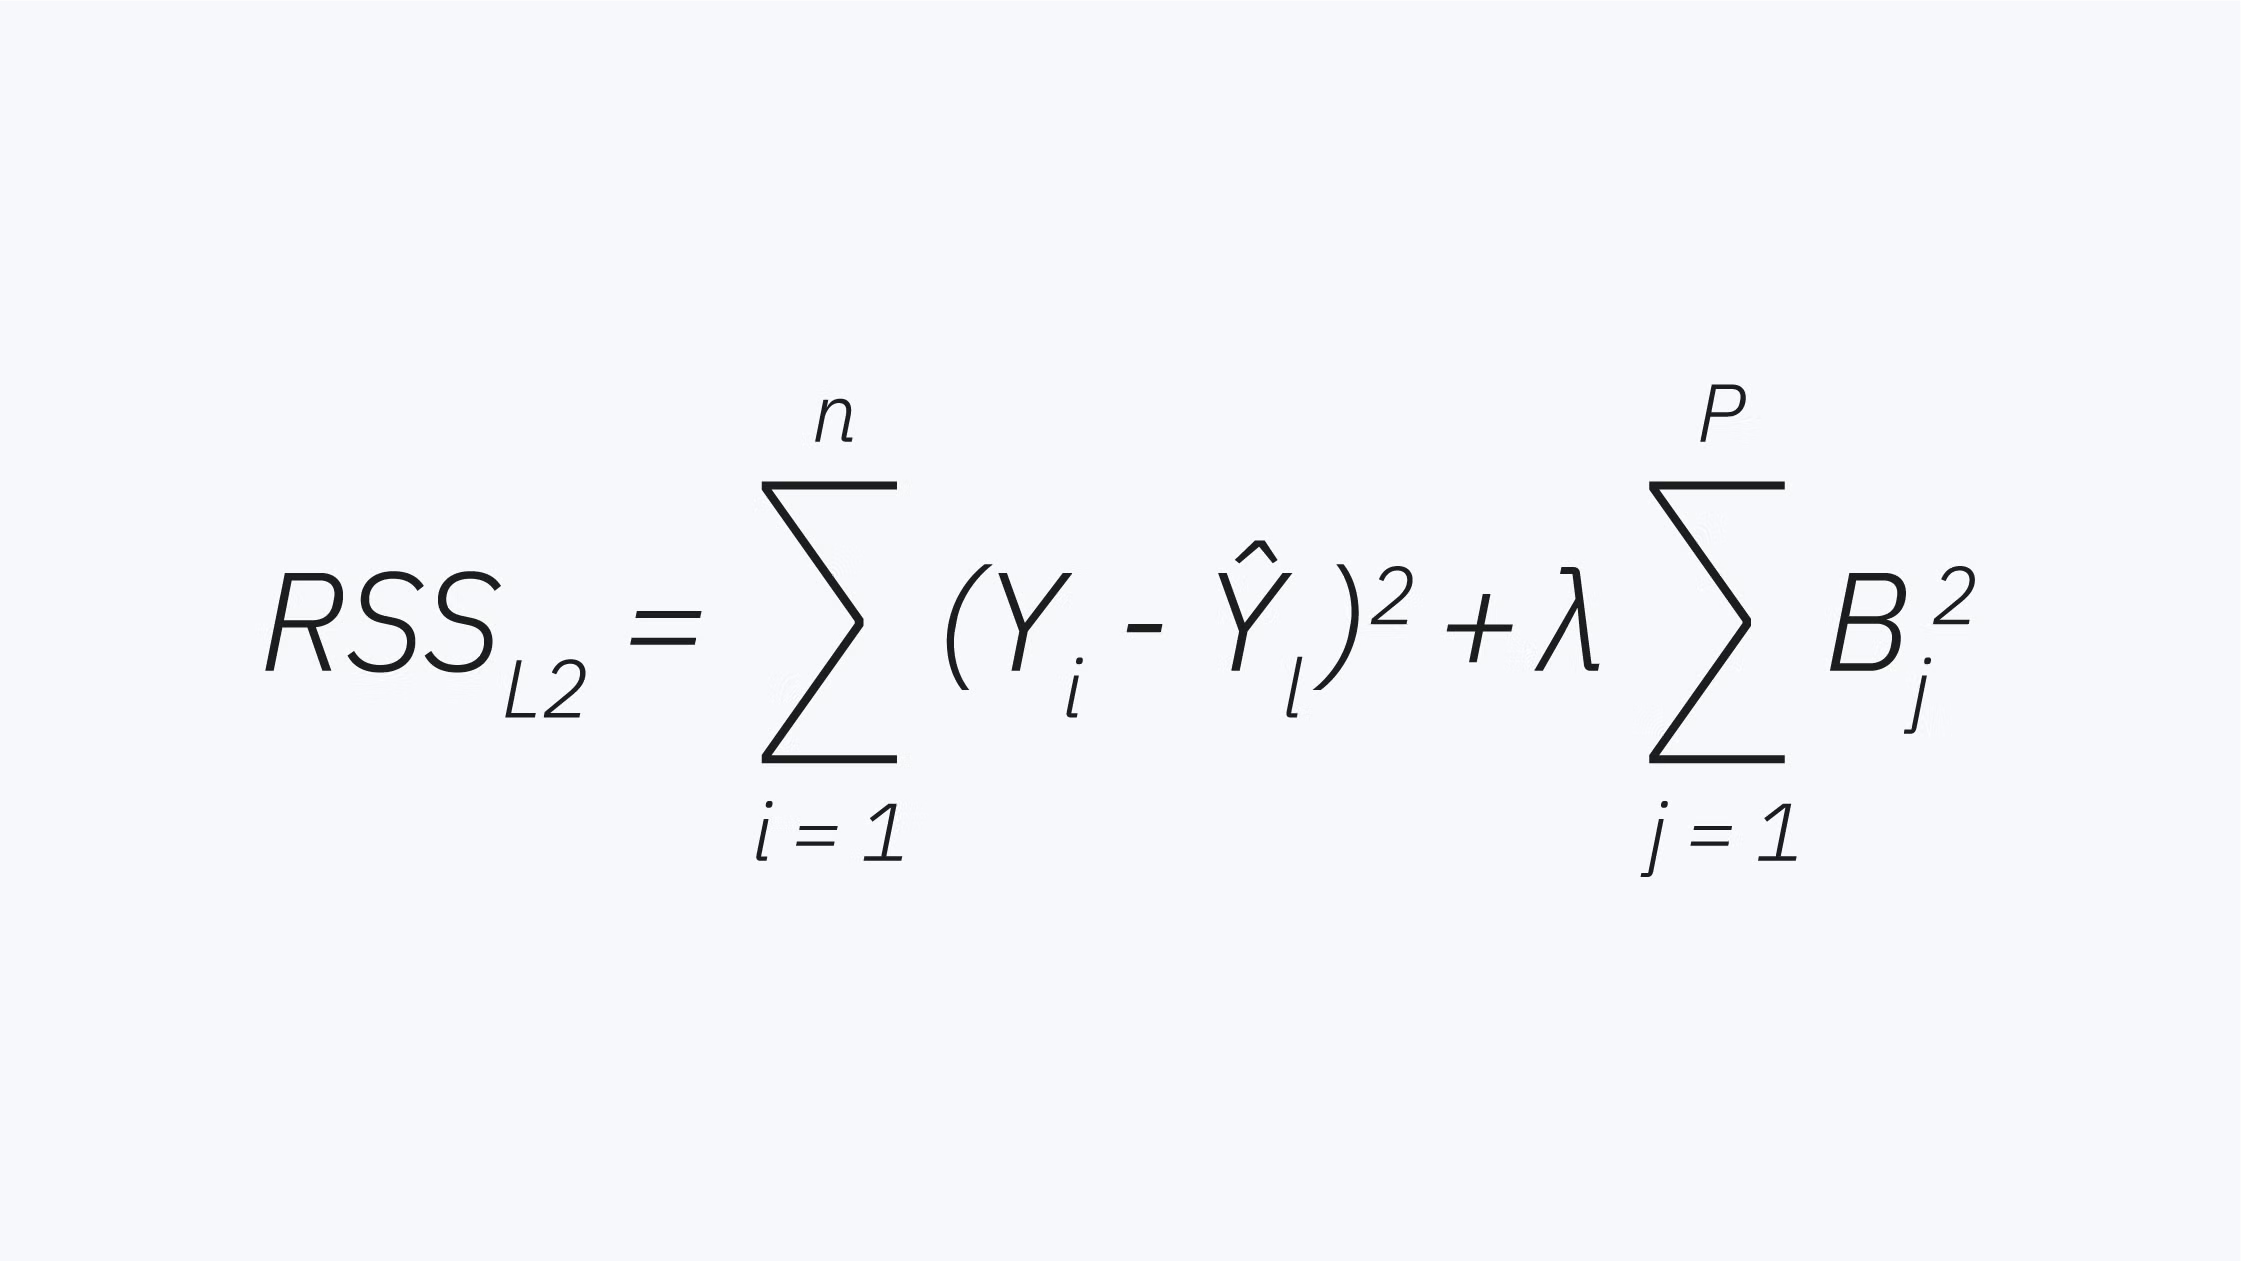

In [36]:
from sklearn.linear_model import SGDRegressor

sgd_reg = SGDRegressor(penalty= 'l2',
                       max_iter = 1000, eta0=0.01, random_state=42)
sgd_reg.fit(X, y.ravel())
sgd_reg.predict([[1.5]])

array([1.47012588])

In [37]:
ridge_reg2 = Ridge(alpha=0.01, solver='sag')
ridge_reg2.fit(X, y)
ridge_reg2.predict([[1.5]])

array([1.55355008])

In [38]:
ridge_reg2.intercept_ , ridge_reg2.coef_

(array([0.97582695]), array([0.38514876]))

##Lasso Regression (L1)

In [39]:
from sklearn.linear_model import Lasso

lasso_reg = Lasso(alpha=0.1)
lasso_reg.fit(X, y)
lasso_reg.predict([[1.5]])

array([1.53788174])

- **Lasso(alpha=0.1)**: Creates a Linear Regression model with L1 Regularization. The alpha hyperparameter controls how strongly you penalize large weights (higher alpha = simpler model).

In [40]:
from sklearn.preprocessing import StandardScaler

def plot_model(model_class, polynomial, alphas, **model_kwargs):
  plt.plot(X, y , 'b.', linewidth = 3)
  for alpha, style, in zip(alphas, ('b:', 'g--', 'r-')):
    if alpha > 0 :
      model = model_class(alpha, **model_kwargs)
    else:
      model = LinearRegression()
    if polynomial:
      model = make_pipeline(
          PolynomialFeatures(degree = 10, include_bias= False),
          StandardScaler(),
          model
      )
    model.fit(X, y)
    y_new_regul = model.predict(X_new)
    plt.plot(X_new, y_new_regul, style, linewidth = 2,
             label=fr'$\alpha = {alpha}$')
  plt.legend(loc='upper left')
  plt.xlabel('x')
  plt.axis([0, 3, 0, 3.5])
  plt.grid()

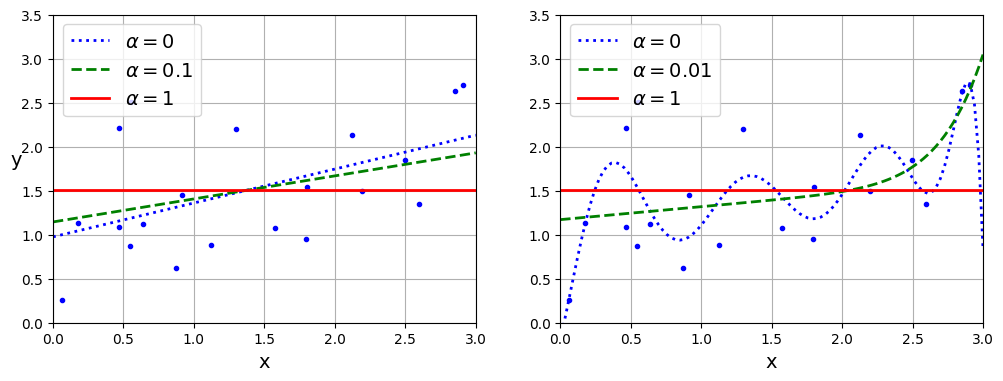

In [41]:
plt.figure(figsize= (12, 4))
plt.subplot(121)
plot_model(Lasso, polynomial=False, alphas=(0, 0.1, 1) , random_state=42)
plt.ylabel('y', rotation=0)
plt.subplot(122)
plot_model(Lasso, polynomial=True, alphas=(0, 1e-2, 1), random_state=42)
plt.show()

- Left Plot (polynomial=False): Fits standard linear models ($y = w \cdot x + b$) using three values of $\alpha$ ($0$, $0.1$, and $1$).
- Right Plot (polynomial=True): Fits high-degree (Degree 10) polynomial models using three values of $\alpha$ ($0$, $0.01$, and $1$).

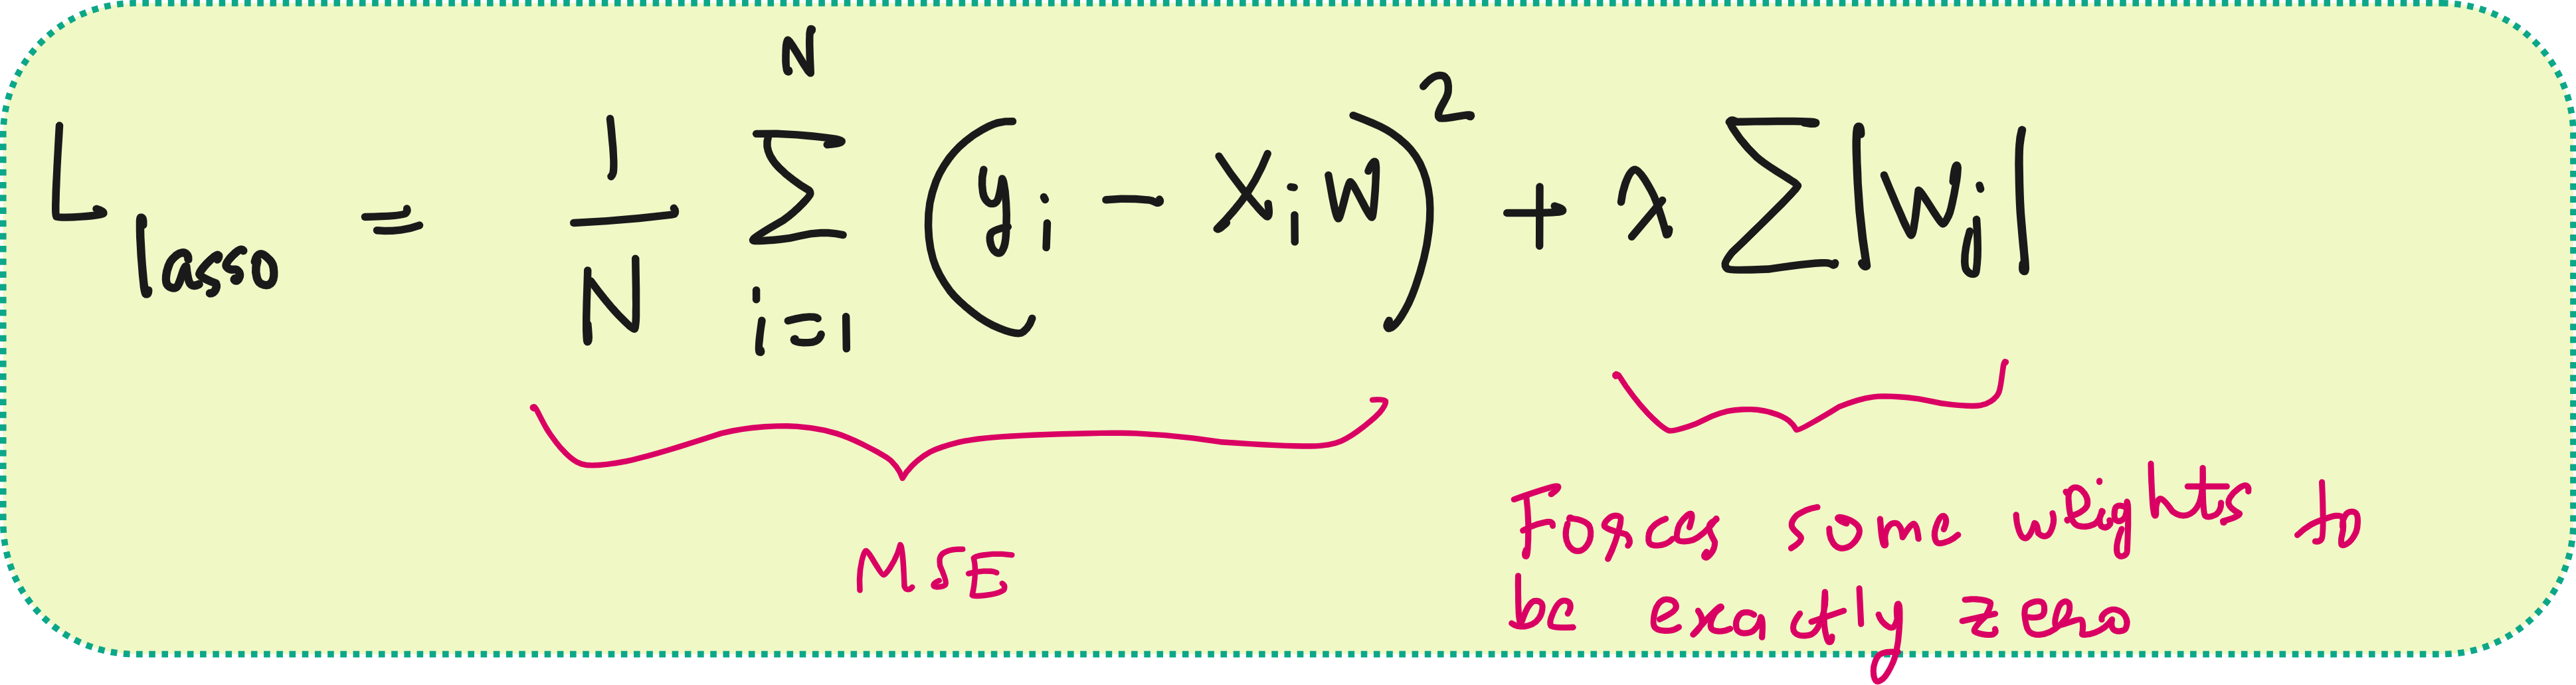

The Core Concept:
- Lasso adds a penalty to the loss function proportional to the absolute values of the weights ($\alpha \sum \vert{}w_i\vert{}$).$\alpha = 0$ (Blue Dotted): Plain Linear Regression (no penalty). In the polynomial plot on the right, it overfits wildly.
- Small $\alpha > 0$ (Green Dashed): Applies mild regularization, smoothing out the extreme polynomial curves.
- Large $\alpha = 1$ (Red Solid): Applies heavy regularization, forcing feature weights down to zero and making the model much simpler to prevent overfitting.

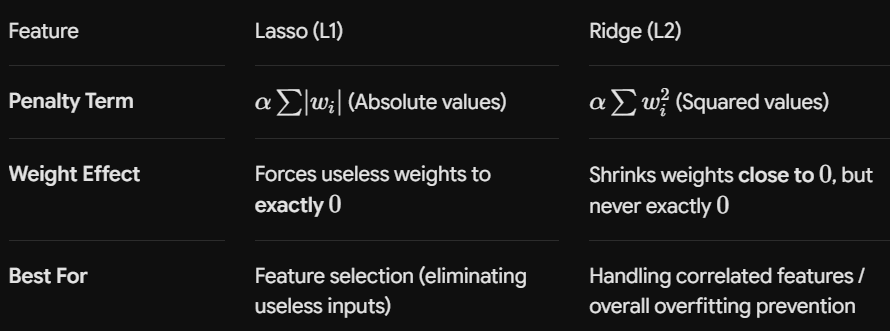

##Elastic Net

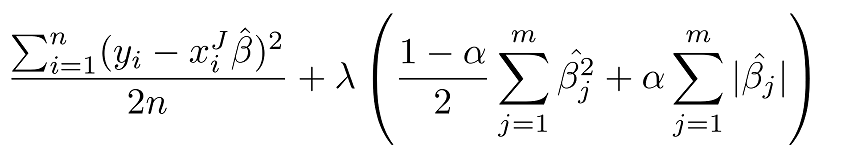

In [42]:
from sklearn.linear_model import ElasticNet

elastic_net = ElasticNet(alpha=0.1, l1_ratio = 0.5)
elastic_net.fit(X, y)
elastic_net.predict([[1.5]])

array([1.54333232])

#Logistic Regression

##Estimating Probablities

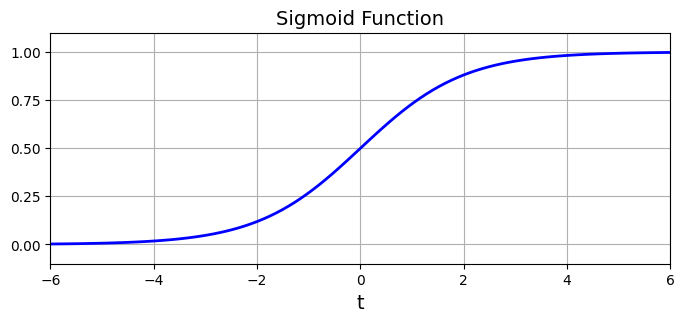

In [43]:
lim = 6
t = np.linspace(-lim, lim, 100)
sig = 1/ (1 + np.exp(-t))

plt.figure(figsize=(8, 3))
plt.plot(t, sig, 'b-', linewidth=2)
plt.xlabel('t')
plt.title("Sigmoid Function")
plt.axis([-lim, lim, -0.1, 1.1])
plt.gca().set_yticks([0, 0.25, 0.5, 0.75, 1])
plt.grid()
plt.show()

**What it does:** It squashes any real number into a probability range strictly between 0.0 and 1.0.   
- Large negative numbers $\rightarrow 0$   
- $0 \rightarrow 0.5$   
- Large positive numbers $\rightarrow 1$

* **Linear Score ($z$):** $z = w_1 x_1 + w_2 x_2 + \dots + b$
* **Sigmoid Formula:** $\sigma(z) = \frac{1}{1 + e^{-z}}$
* **Role:** Squashes any continuous value $z \in (-\infty, +\infty)$ into a valid probability range $[0, 1]$.
* **Decision Rule:**

$$\hat{y} = \begin{cases} 1 & \text{if } \sigma(z) \ge 0.5 \ (z \ge 0) \\ 0 & \text{if } \sigma(z) < 0.5 \ (z < 0) \end{cases}$$

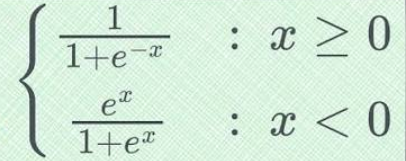

##Decision Boundaries

In [44]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame = True)
list(iris)

['data',
 'target',
 'frame',
 'target_names',
 'DESCR',
 'feature_names',
 'filename',
 'data_module']

In [45]:
iris.data.head(3)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


In [46]:
iris.target.head(3)

,target
0,0
1,0
2,0


In [47]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split


X = iris.data[['petal width (cm)']].values
y = iris.target_names[iris.target] == 'virginica'
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)


log_reg = LogisticRegression(random_state = 42)
log_reg.fit(X_train, y_train)

LogisticRegression(random_state=42)

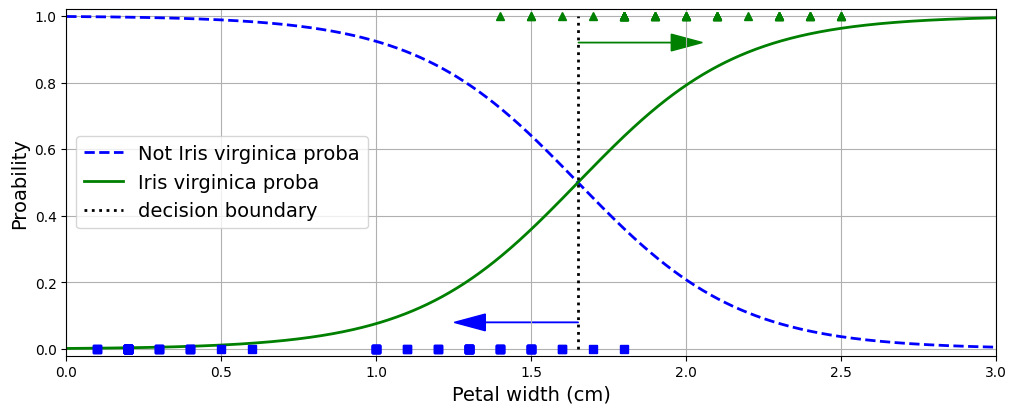

In [49]:
X_new = np.linspace(0, 3, 1000).reshape(-1, 1)    # reshape to get a column vector
y_proba = log_reg.predict_proba(X_new)
decision_boundary = X_new[y_proba[:, 1] >= 0.5][0, 0]

plt.figure(figsize=(12, 4.5))
plt.plot(X_new, y_proba[:, 0], 'b--', linewidth=2,
         label='Not Iris virginica proba')
plt.plot(X_new, y_proba[:, 1], 'g-', linewidth=2, label='Iris virginica proba')
plt.plot([decision_boundary, decision_boundary], [0, 1], 'k:', linewidth=2,
         label='decision boundary')

plt.arrow(x=decision_boundary, y=0.08, dx=-0.3, dy=0,
          head_width=0.05, head_length=0.1, fc='b', ec='b')
plt.arrow(x=decision_boundary, y=0.92, dx=0.3, dy=0,
          head_width=0.05, head_length=0.1, fc='g', ec='g')

plt.plot(X_train[y_train == 0], y_train[y_train == 0], 'bs')
plt.plot(X_train[y_train == 1], y_train[y_train == 1], 'g^')


plt.xlabel('Petal width (cm)')
plt.ylabel('Proability')
plt.legend(loc = 'center left')
plt.axis([0, 3, -0.02, 1.02])
plt.grid()
plt.show()